# Reyhana Abdikher
# AnalystLab Africa Week2 Track2 (Data Science)

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.dpi'] = 150

# Task 1 Data Exploration & Preparation
 

In [17]:
# Load datasets
sessions = pd.read_csv('website_sessions.csv')
pageviews = pd.read_csv('website_pageviews.csv')
orders = pd.read_csv('orders_mav.csv')
order_items = pd.read_csv('order_items.csv')
refunds = pd.read_csv('order_item_refunds.csv')
products = pd.read_csv('products.csv')

datasets = {
    'website_sessions': sessions,
    'website_pageviews': pageviews,
    'orders_mav': orders,
    'order_items': order_items,
    'order_item_refunds': refunds,
    'products': products
}

for name, df in datasets.items():
    print(f"=== {name} ===")
    print(f"Shape: {df.shape} | Duplicates: {df.duplicated().sum()}")
    nulls = df.isnull().sum()
    if nulls.sum() > 0:
        print("Missing values:\n", nulls[nulls > 0])
    print()

=== website_sessions ===
Shape: (472871, 9) | Duplicates: 0
Missing values:
 utm_source      83328
utm_campaign    83328
utm_content     83328
http_referer    39917
dtype: int64

=== website_pageviews ===
Shape: (1048575, 4) | Duplicates: 0

=== orders_mav ===
Shape: (32313, 8) | Duplicates: 0

=== order_items ===
Shape: (40025, 7) | Duplicates: 0

=== order_item_refunds ===
Shape: (1731, 5) | Duplicates: 0

=== products ===
Shape: (4, 3) | Duplicates: 0



In [18]:
# Convert created_at timestamps to datetime
for df in datasets.values():
    df['created_at'] = pd.to_datetime(df['created_at'])

# Clean missing marketing attribution values in website_sessions
sessions['utm_source_clean'] = sessions['utm_source'].fillna('direct / organic')
sessions['utm_campaign_clean'] = sessions['utm_campaign'].fillna('none')
sessions['utm_content_clean'] = sessions['utm_content'].fillna('none')
sessions['http_referer_clean'] = sessions['http_referer'].fillna('direct')

print("Date ranges verified:")
print("Sessions:", sessions['created_at'].min(), "to", sessions['created_at'].max())
print("Orders:  ", orders['created_at'].min(), "to", orders['created_at'].max())

Date ranges verified:
Sessions: 2012-03-19 08:04:00 to 2015-03-19 07:59:00
Orders:   2012-03-19 10:42:00 to 2015-03-19 05:38:00


# Task 2 Exploratory Data Analysis 
 

In [19]:
# Q1 Revenue & Orders Over Time
orders['year_month'] = orders['created_at'].dt.to_period('M')
orders['year'] = orders['created_at'].dt.year

monthly_perf = orders.groupby('year_month').agg(
    orders_count=('order_id', 'count'),
    revenue=('price_usd', 'sum'),
    cogs=('cogs_usd', 'sum'),
    aov=('price_usd', 'mean')
).reset_index()
monthly_perf['profit'] = monthly_perf['revenue'] - monthly_perf['cogs']
monthly_perf['ym_str'] = monthly_perf['year_month'].astype(str)

print("--- Yearly Revenue Summary ---")
print(orders.groupby('year').agg(
    orders=('order_id', 'count'),
    revenue=('price_usd', 'sum'),
    aov=('price_usd', 'mean')
).round(2))
print("\nHighest Revenue Month:", monthly_perf.loc[monthly_perf['revenue'].idxmax()][['ym_str', 'revenue', 'orders_count']].to_dict())
print("Lowest Revenue Month: ", monthly_perf.loc[monthly_perf['revenue'].idxmin()][['ym_str', 'revenue', 'orders_count']].to_dict())

--- Yearly Revenue Summary ---
      orders     revenue    aov
year                           
2012    2586   129274.14  49.99
2013    7447   393247.87  52.81
2014   16860  1075612.19  63.80
2015    5420   340375.55  62.80

Highest Revenue Month: {'ym_str': '2014-12', 'revenue': 144823.02000000002, 'orders_count': 2314}
Lowest Revenue Month:  {'ym_str': '2012-03', 'revenue': 2999.4, 'orders_count': 60}


In [20]:
# Q2 Product Performance
items_prod = order_items.merge(products[['product_id', 'product_name']], on='product_id', how='left')
prod_perf = items_prod.groupby(['product_id', 'product_name']).agg(
    units_sold=('order_item_id', 'count'),
    primary_units=('is_primary_item', 'sum'),
    revenue=('price_usd', 'sum'),
    cogs=('cogs_usd', 'sum'),
    unit_price=('price_usd', 'mean')
).reset_index()
prod_perf['cross_sell_units'] = prod_perf['units_sold'] - prod_perf['primary_units']
prod_perf['margin'] = prod_perf['revenue'] - prod_perf['cogs']
prod_perf['margin_pct'] = (prod_perf['margin'] / prod_perf['revenue']) * 100

print("--- Product Performance ---")
display(prod_perf.round(2))

--- Product Performance ---


,product_id,product_name,units_sold,primary_units,revenue,cogs,unit_price,cross_sell_units,margin,margin_pct
0,1,The Original Mr. Fuzzy,24226,23861,1211057.74,472164.74,49.99,365,738893.0,61.01
1,2,The Forever Love Bear,5796,4803,347702.04,130352.04,59.99,993,217350.0,62.51
2,3,The Birthday Sugar Panda,4985,3068,229260.15,72232.65,45.99,1917,157027.5,68.49
3,4,The Hudson River Mini bear,5018,581,150489.82,47620.82,29.99,4437,102869.0,68.36


In [21]:
# Q3 Customer Purchasing Behaviour
user_orders = orders.groupby('user_id').agg(
    order_count=('order_id', 'count'),
    total_spent=('price_usd', 'sum')
)
print(f"Unique Buyers: {len(user_orders):,}")
print(f"Repeat Buyers (>1 order): {(user_orders['order_count'] > 1).sum():,} ({(user_orders['order_count'] > 1).mean()*100:.2f}%)")
print("\nItems per Order (%):\n", (orders['items_purchased'].value_counts(normalize=True)*100).round(2))
print("\nOrders by Day of Week:\n", orders['created_at'].dt.day_name().value_counts())

Unique Buyers: 31,696
Repeat Buyers (>1 order): 591 (1.86%)

Items per Order (%):
 items_purchased
1    76.13
2    23.87
Name: proportion, dtype: float64

Orders by Day of Week:
 created_at
Monday       5662
Friday       5571
Wednesday    5499
Thursday     5414
Tuesday      5320
Sunday       2538
Saturday     2309
Name: count, dtype: int64


In [22]:
# Q4, Q5, Q6, Q8 Sessions, Marketing Channels, Devices & Repeat Sessions
sess_orders = sessions.merge(orders[['website_session_id', 'order_id', 'price_usd']], on='website_session_id', how='left')
sess_orders['converted'] = sess_orders['order_id'].notnull().astype(int)

print(f"Overall Conversion Rate: {sess_orders['converted'].mean()*100:.2f}% ({sess_orders['converted'].sum():,} orders / {len(sess_orders):,} sessions)\n")

chan_perf = sess_orders.groupby('utm_source_clean').agg(
    sessions=('website_session_id', 'count'),
    orders=('converted', 'sum'),
    conv_rate=('converted', lambda x: x.mean()*100),
    revenue=('price_usd', 'sum')
).sort_values('sessions', ascending=False)
print("--- Marketing Channels ---")
display(chan_perf.round(2))

dev_perf = sess_orders.groupby('device_type').agg(
    sessions=('website_session_id', 'count'),
    orders=('converted', 'sum'),
    conv_rate=('converted', lambda x: x.mean()*100),
    revenue=('price_usd', 'sum')
)
print("--- Device Type ---")
display(dev_perf.round(2))

rep_perf = sess_orders.groupby('is_repeat_session').agg(
    sessions=('website_session_id', 'count'),
    orders=('converted', 'sum'),
    conv_rate=('converted', lambda x: x.mean()*100),
    aov=('price_usd', 'mean')
)
print("--- New (0) vs Returning (1) Sessions ---")
display(rep_perf.round(2))

Overall Conversion Rate: 6.83% (32,313 orders / 472,871 sessions)

--- Marketing Channels ---


,sessions,orders,conv_rate,revenue
utm_source_clean,,,,
gsearch,316035,21333,6.75,1276144.89
direct / organic,83328,6118,7.34,371433.03
bsearch,62823,4519,7.19,268672.50
socialbook,10685,343,3.21,22259.33


--- Device Type ---


,sessions,orders,conv_rate,revenue
device_type,,,,
desktop,327027,27805,8.50,1665757.84
mobile,145844,4508,3.09,272751.91


--- New (0) vs Returning (1) Sessions ---


,sessions,orders,conv_rate,aov
is_repeat_session,,,,
0,394318,26164,6.64,59.86
1,78553,6149,7.83,60.54


In [23]:
# Q7 Product Refund Activity
items_refunds = items_prod.merge(refunds[['order_item_id', 'refund_amount_usd']], on='order_item_id', how='left')
items_refunds['is_refunded'] = items_refunds['refund_amount_usd'].notnull().astype(int)
items_refunds['year_month'] = items_refunds['created_at'].dt.to_period('M')

ref_prod = items_refunds.groupby(['product_id', 'product_name']).agg(
    units_sold=('order_item_id', 'count'),
    refund_count=('is_refunded', 'sum'),
    refund_rate=('is_refunded', lambda x: x.mean()*100),
    refund_usd=('refund_amount_usd', 'sum')
).reset_index()

print(f"Total Refunds: {len(refunds):,} | Total Refunded USD: ${refunds['refund_amount_usd'].sum():,.2f}")
display(ref_prod.round(2))

Total Refunds: 1,731 | Total Refunded USD: $85,338.69


,product_id,product_name,units_sold,refund_count,refund_rate,refund_usd
0,1,The Original Mr. Fuzzy,24226,1237,5.11,61837.63
1,2,The Forever Love Bear,5796,129,2.23,7738.71
2,3,The Birthday Sugar Panda,4985,301,6.04,13842.99
3,4,The Hudson River Mini bear,5018,64,1.28,1919.36


# Task 3 Statistical Analysis & Six Visualisations
 

In [24]:
# Descriptive statistics
print("--- Order Descriptive Statistics ---")
display(orders[['items_purchased', 'price_usd', 'cogs_usd']].describe().round(2))

# Monthly traffic vs orders correlation
sessions['year_month'] = sessions['created_at'].dt.to_period('M')
monthly_sess = sessions.groupby('year_month').size().reset_index(name='sessions')
monthly_full = monthly_sess.merge(monthly_perf, on='year_month', how='left')

r_sess_ord, p_sess_ord = stats.pearsonr(monthly_full['sessions'], monthly_full['orders_count'])
chi2_dev, p_dev, _, _ = stats.chi2_contingency(pd.crosstab(sess_orders['device_type'], sess_orders['converted']))
chi2_rep, p_rep, _, _ = stats.chi2_contingency(pd.crosstab(sess_orders['is_repeat_session'], sess_orders['converted']))

print(f"Pearson r (Monthly Sessions vs Orders): r = {r_sess_ord:.4f}, p = {p_sess_ord:.4e}")
print(f"Chi-square (Device Type vs Conversion): chi2 = {chi2_dev:.2f}, p = {p_dev:.4e}")
print(f"Chi-square (Repeat Session vs Conversion): chi2 = {chi2_rep:.2f}, p = {p_rep:.4e}")

--- Order Descriptive Statistics ---


,items_purchased,price_usd,cogs_usd
count,32313.00,32313.00,32313.00
mean,1.24,59.99,22.36
std,0.43,17.81,6.24
min,1.00,29.99,9.49
25%,1.00,49.99,19.49
50%,1.00,49.99,19.49
75%,1.00,59.99,22.49
max,2.00,109.98,41.98


Pearson r (Monthly Sessions vs Orders): r = 0.9838, p = 1.0177e-27
Chi-square (Device Type vs Conversion): chi2 = 4638.43, p = 0.0000e+00
Chi-square (Repeat Session vs Conversion): chi2 = 146.15, p = 1.2051e-33


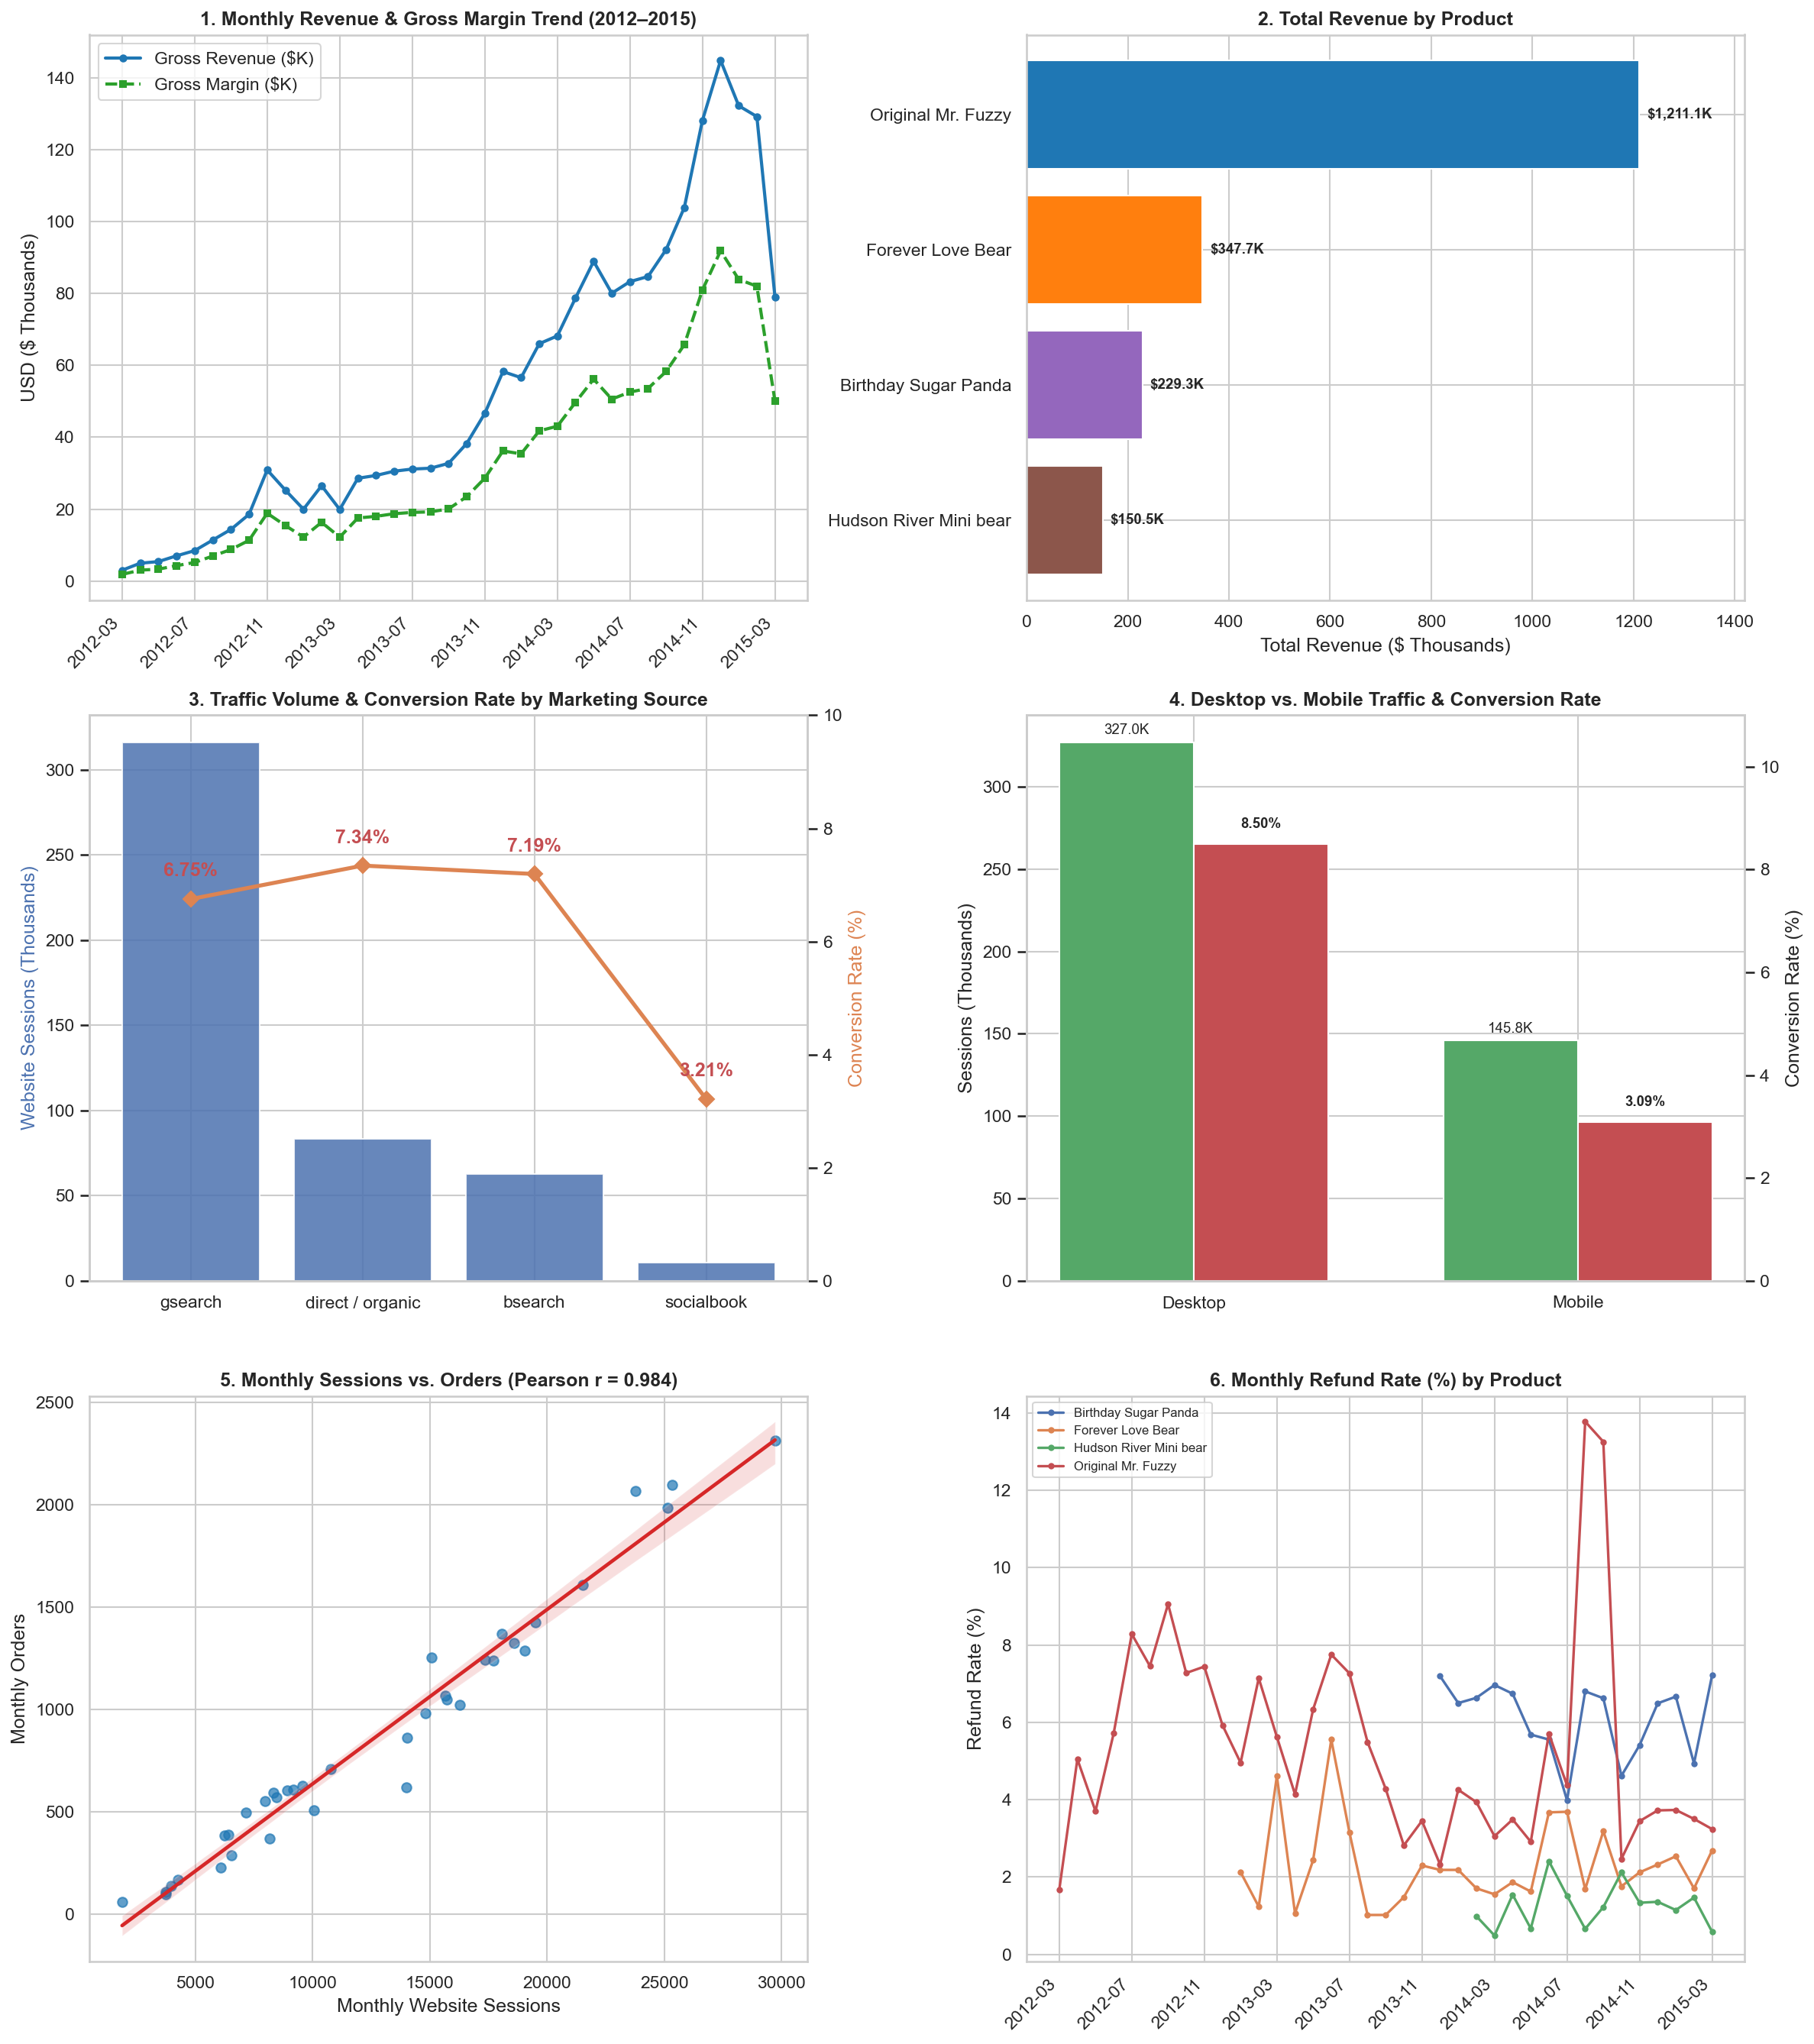

In [25]:
# Six Meaningful Visualisations
ref_trend = items_refunds.groupby(['year_month', 'product_name']).agg(
    sold=('order_item_id', 'count'),
    refunded=('is_refunded', 'sum')
).reset_index()
ref_trend['refund_rate'] = (ref_trend['refunded'] / ref_trend['sold']) * 100

fig, axes = plt.subplots(3, 2, figsize=(16, 18))
plt.subplots_adjust(hspace=0.42, wspace=0.28)

# 1. Monthly Revenue & Gross Margin Trend
ax1 = axes[0, 0]
x_idx = range(len(monthly_full))
ax1.plot(x_idx, monthly_full['revenue'] / 1000, marker='o', markersize=4, linewidth=2, label='Gross Revenue ($K)', color='#1f77b4')
ax1.plot(x_idx, monthly_full['profit'] / 1000, marker='s', markersize=4, linewidth=2, linestyle='--', label='Gross Margin ($K)', color='#2ca02c')
ax1.set_title('1. Monthly Revenue & Gross Margin Trend (2012–2015)', fontsize=12, fontweight='bold')
ax1.set_ylabel('USD ($ Thousands)')
ax1.set_xticks(list(x_idx)[::4])
ax1.set_xticklabels(monthly_full['ym_str'].iloc[::4], rotation=45, ha='right')
ax1.legend()

# 2. Total Revenue by Product
ax2 = axes[0, 1]
prod_sorted = prod_perf.sort_values('revenue', ascending=True)
y_pos = np.arange(len(prod_sorted))
ax2.barh(y_pos, prod_sorted['revenue'] / 1000, color=['#8c564b', '#9467bd', '#ff7f0e', '#1f77b4'])
ax2.set_yticks(y_pos)
ax2.set_yticklabels([n.replace('The ', '') for n in prod_sorted['product_name']])
ax2.set_xlabel('Total Revenue ($ Thousands)')
ax2.set_title('2. Total Revenue by Product', fontsize=12, fontweight='bold')
for i, v in enumerate(prod_sorted['revenue'] / 1000):
    ax2.text(v + 15, i, f'${v:,.1f}K', va='center', fontsize=9, fontweight='bold')
ax2.set_xlim(0, 1420)

# 3. Traffic Volume & Conversion Rate by Marketing Source
ax3 = axes[1, 0]
chan_reset = chan_perf.reset_index()
ax3.bar(chan_reset['utm_source_clean'], chan_reset['sessions'] / 1000, color='#4c72b0', alpha=0.85, label='Sessions (K)')
ax3.set_ylabel('Website Sessions (Thousands)', color='#4c72b0')
ax3.set_title('3. Traffic Volume & Conversion Rate by Marketing Source', fontsize=12, fontweight='bold')
ax3_twin = ax3.twinx()
ax3_twin.plot(chan_reset['utm_source_clean'], chan_reset['conv_rate'], color='#dd8452', marker='D', linewidth=2.5, markersize=7)
ax3_twin.set_ylabel('Conversion Rate (%)', color='#dd8452')
ax3_twin.set_ylim(0, 10)
ax3_twin.grid(False)
for i, rate in enumerate(chan_reset['conv_rate']):
    ax3_twin.annotate(f'{rate:.2f}%', (i, rate + 0.4), ha='center', fontweight='bold', color='#c44e52')

# 4. Desktop vs. Mobile Traffic & Conversion Rate
ax4 = axes[1, 1]
dev_reset = dev_perf.reset_index()
x_dev = np.arange(len(dev_reset))
width = 0.35
b1 = ax4.bar(x_dev - width/2, dev_reset['sessions'] / 1000, width, color='#55a868')
ax4.set_ylabel('Sessions (Thousands)')
ax4.set_xticks(x_dev)
ax4.set_xticklabels(dev_reset['device_type'].str.capitalize())
ax4.set_title('4. Desktop vs. Mobile Traffic & Conversion Rate', fontsize=12, fontweight='bold')
ax4_twin = ax4.twinx()
b2 = ax4_twin.bar(x_dev + width/2, dev_reset['conv_rate'], width, color='#c44e52')
ax4_twin.set_ylabel('Conversion Rate (%)')
ax4_twin.set_ylim(0, 11)
ax4_twin.grid(False)
for bar in b1:
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5, f'{bar.get_height():.1f}K', ha='center', fontsize=9)
for bar in b2:
    ax4_twin.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f'{bar.get_height():.2f}%', ha='center', fontsize=9, fontweight='bold')

# 5. Monthly Sessions vs. Orders Regression Scatter
ax5 = axes[2, 0]
sns.regplot(data=monthly_full, x='sessions', y='orders_count', ax=ax5, scatter_kws={'alpha':0.7, 'color':'#1f77b4'}, line_kws={'color':'#d62728'})
ax5.set_title(f'5. Monthly Sessions vs. Orders (Pearson r = {r_sess_ord:.3f})', fontsize=12, fontweight='bold')
ax5.set_xlabel('Monthly Website Sessions')
ax5.set_ylabel('Monthly Orders')

# 6. Monthly Refund Rate Trend by Product
ax6 = axes[2, 1]
piv_ref = ref_trend.pivot(index='year_month', columns='product_name', values='refund_rate').sort_index()
x_ref = np.arange(len(piv_ref))
for col in piv_ref.columns:
    ax6.plot(x_ref, piv_ref[col], marker='o', markersize=3, linewidth=1.6, label=col.replace('The ', ''))
ax6.set_title('6. Monthly Refund Rate (%) by Product', fontsize=12, fontweight='bold')
ax6.set_ylabel('Refund Rate (%)')
ax6.set_xticks(x_ref[::4])
ax6.set_xticklabels([str(p) for p in piv_ref.index[::4]], rotation=45, ha='right')
ax6.legend(fontsize=8, loc='upper left')

plt.tight_layout()
plt.savefig('track2_eda_visualizations.png', dpi=200)
plt.show()